<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 14: Unfolded RNN Architecture Visualization

**Category**: CO3 – Sequence Models (RNN, LSTM, GRU)  
**Objective**: Simulate forward temporal state transitions and visualize unfolded recurrent graph computation with parameter sharing.


### Task 1: Recurrent Cell Computations and Hidden State Forward Flow


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(101)
T = 6 # Sequence length
D_in = 2
D_hid = 3
D_out = 1

# Shared recurrent parameters
W_xh = np.random.randn(D_hid, D_in) * 0.5
W_hh = np.random.randn(D_hid, D_hid) * 0.5
b_h  = np.zeros((D_hid, 1))

W_hy = np.random.randn(D_out, D_hid) * 0.5
b_y  = np.zeros((D_out, 1))

# Simulated sequence x_1, x_2, ..., x_T
X_stream = np.random.randn(T, D_in, 1)

h_states = [np.zeros((D_hid, 1))] # h_0 = 0
outputs = []

for t in range(T):
    x_t = X_stream[t]
    h_prev = h_states[-1]
    # Recurrent transition: h_t = tanh(W_xh * x_t + W_hh * h_{t-1} + b_h)
    h_t = np.tanh(np.dot(W_xh, x_t) + np.dot(W_hh, h_prev) + b_h)
    h_states.append(h_t)
    # Output: y_t = W_hy * h_t + b_y
    y_t = np.dot(W_hy, h_t) + b_y
    outputs.append(y_t.ravel()[0])

print(f"Shared Recurrent Weight Matrix Shapes:")
print(f"W_xh: {W_xh.shape}, W_hh: {W_hh.shape}, W_hy: {W_hy.shape}")
print("\nGenerated Output Sequence y_1 .. y_6:\n", np.round(outputs, 3))


Shared Recurrent Weight Matrix Shapes:
W_xh: (3, 2), W_hh: (3, 3), W_hy: (1, 3)

Generated Output Sequence y_1 .. y_6:
 [ 1.183 -0.458 -0.851  0.37   0.038  0.532]


### Task 2: Diagrammatic Visualization of Unfolded Computations Across Time


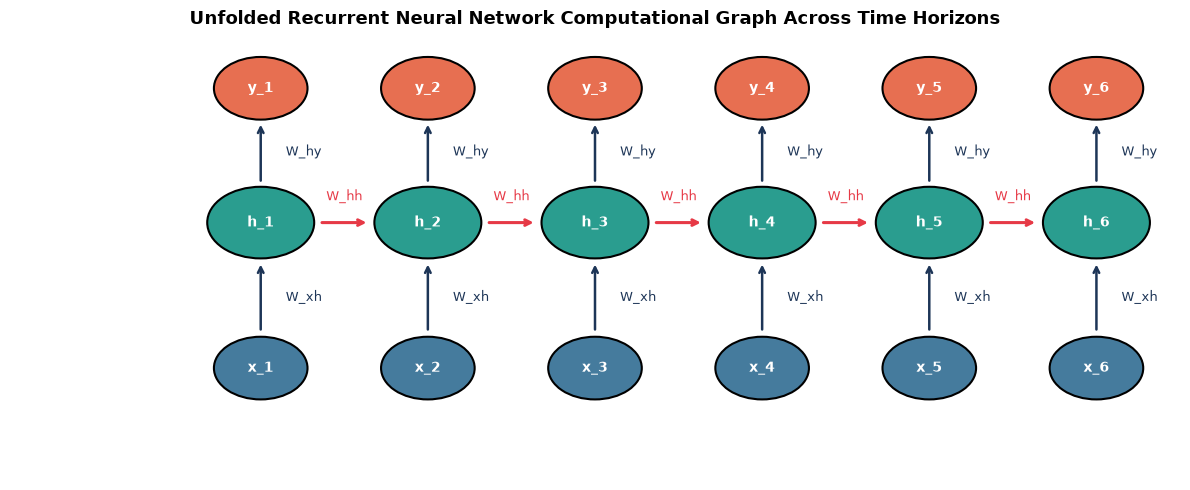

In [2]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.set_xlim(-0.5, T + 0.5)
ax.set_ylim(-0.5, 3.5)
ax.axis('off')

for t in range(1, T + 1):
    # Draw x_t (bottom)
    ax.add_patch(plt.Circle((t, 0.5), 0.28, color='#457b9d', ec='k', lw=1.5))
    ax.text(t, 0.5, f"x_{t}", ha='center', va='center', color='w', fontweight='bold')

    # Draw h_t (middle)
    ax.add_patch(plt.Circle((t, 1.8), 0.32, color='#2a9d8f', ec='k', lw=1.5))
    ax.text(t, 1.8, f"h_{t}", ha='center', va='center', color='w', fontweight='bold')

    # Draw y_t (top)
    ax.add_patch(plt.Circle((t, 3.0), 0.28, color='#e76f51', ec='k', lw=1.5))
    ax.text(t, 3.0, f"y_{t}", ha='center', va='center', color='w', fontweight='bold')

    # Arrow x_t -> h_t (W_xh)
    ax.annotate("", xy=(t, 1.45), xytext=(t, 0.82), arrowprops=dict(arrowstyle="->", lw=1.8, color='#1d3557'))
    ax.text(t + 0.15, 1.1, "W_xh", fontsize=9, color='#1d3557')

    # Arrow h_t -> y_t (W_hy)
    ax.annotate("", xy=(t, 2.7), xytext=(t, 2.15), arrowprops=dict(arrowstyle="->", lw=1.8, color='#1d3557'))
    ax.text(t + 0.15, 2.4, "W_hy", fontsize=9, color='#1d3557')

    # Arrow h_{t-1} -> h_t (W_hh)
    if t < T:
        ax.annotate("", xy=(t + 0.65, 1.8), xytext=(t + 0.35, 1.8), arrowprops=dict(arrowstyle="->", lw=2.2, color='#e63946'))
        ax.text(t + 0.5, 2.0, "W_hh", fontsize=9, color='#e63946', ha='center')

plt.title("Unfolded Recurrent Neural Network Computational Graph Across Time Horizons", fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()
